# 02 — Selección del grupo: correlación, Engle–Granger y Johansen

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · Guía: `docs/instrucciones/02_cointegracion.md`

Este notebook **solo muestra** lo que calcula `python main.py` (etapa 2). Lee los artefactos de `artifacts/` y llama
funciones de `cointegration/`; no contiene lógica propia. Todo lo que se estima aquí usa **solo entrenamiento**
(2012-01-03 → 2020-11-19).

Criterio fijado **antes** de correr el embudo (`docs/decisiones.md`, commit `43d84d7`):

| # | Etapa | Regla |
|---|---|---|
| 2 | Correlación | media de las 6 correlaciones por pares (móvil 252 d, rendimientos log) > 0.7 → **elimina** |
| 3 | Engle–Granger | pares y grupo, p < 0.05 → **solo prioriza** |
| 4 | Johansen | la traza rechaza r = 0 al 95 % → **elimina** |
| 5 | Vector | entre las r̂ columnas con vida media en [5, 60] días, menor p ADF |
| 6 | Validación | ADF del spread p < 0.05 y vida media en [5, 60] días → **elimina** |
| 7 | Estabilidad | Johansen en cada mitad de train y Johansen móvil → se reporta |
| — | Elección | mayor LR_traza(0) / valor crítico 95 % entre los sobrevivientes |

In [1]:
import json
import sys
from math import comb
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from cointegration.engle_granger import engle_granger, pairwise_engle_granger
from cointegration.johansen import ANCHOR_TICKER, ROLLING_WINDOW, SIGN_CONVENTION, build_spread, summarize_rolling
from cointegration.selection import CORR_THRESHOLD, HALF_LIFE_RANGE
from cointegration.universe import UNIVERSES, all_tickers
from data.clean import clean_prices
from data.download import load_prices
from data.split import N_ASSETS, load_split_dates, slice_split
from main import ARTIFACTS, DATA_SNAPSHOT, END_DATE, FIGURES, START_DATE

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

table = pd.read_csv(ARTIFACTS / "selection_table.csv")
summary = json.loads((ARTIFACTS / "johansen_summary.json").read_text())
comparison = pd.read_csv(ARTIFACTS / "vector_comparison.csv")
rolling = pd.read_parquet(ARTIFACTS / "rolling_eigenvector.parquet")

split_dates = load_split_dates(ARTIFACTS / "split_dates.json")
prices, _ = clean_prices(load_prices(all_tickers(), START_DATE, END_DATE, DATA_SNAPSHOT))
train = slice_split(prices, split_dates, "train")
print(f"Entrenamiento: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} días)")

Entrenamiento: 2012-01-03 → 2020-11-19 (2237 días)


## Paso 1 — Universo y número de grupos probados

Dos universos con justificación económica (`cointegration/universe.py`). Se prueban **todos** los grupos de 4 de
cada uno: C(9, 4) + C(8, 4). Ese total es el que se reporta para la discusión de pruebas múltiples.

In [2]:
counts = pd.DataFrame({
    name: {"activos": len(spec["tickers"]), "grupos de 4": comb(len(spec["tickers"]), N_ASSETS),
           "tickers": ", ".join(spec["tickers"])}
    for name, spec in UNIVERSES.items()
}).T
print("Total de grupos evaluados:", len(table))
counts

Total de grupos evaluados: 196


,activos,grupos de 4,tickers
petroleras,9,126,"XOM, CVX, COP, OXY, EOG, DVN, APA, BP, SHEL"
oro,8,70,"GLD, GDX, NEM, AEM, KGC, B, AU, FNV"


## Resultado del embudo: en qué etapa se descartó cada grupo

In [3]:
funnel = (table.assign(etapa=table["discard_stage"].fillna("sobrevive"))
          .groupby(["universe", "etapa"], sort=False).size().unstack(fill_value=0))
funnel

etapa,2_correlacion,4_johansen,sobrevive
universe,,,
petroleras,122,4,0
oro,4,57,9


## Paso 2 — Correlación móvil de rendimientos

La correlación es solo una heurística: se calcula sobre **rendimientos** (la de dos precios I(1) es alta casi siempre).
Las petroleras casi nunca pasan 0.7; el universo de oro sí.

In [4]:
table.groupby("universe")[["corr_mean", "corr_min_pair", "corr_frac_above"]].describe().T.round(3)

universe                  oro  petroleras
corr_mean       count 70.0000    126.0000
                mean   0.7490      0.6550
                std    0.0360      0.0220
                min    0.6800      0.6120
                25%    0.7180      0.6410
                50%    0.7500      0.6540
                75%    0.7790      0.6670
                max    0.8190      0.7150
corr_min_pair   count 70.0000    126.0000
                mean   0.6840      0.5890
                std    0.0230      0.0310
                min    0.6570      0.5450
                25%    0.6740      0.5710
                50%    0.6760      0.5850
                75%    0.7020      0.6060
                max    0.7540      0.6750
corr_frac_above count 70.0000    126.0000
                mean   0.7690      0.3560
                std    0.1560      0.0850
                min    0.4430      0.1180
                25%    0.6470      0.3110
                50%    0.7540      0.3540
                75%    0.9130      0.4110
                max    1.0000      0.6080

**Correlación por par vs regla de grupo.** A nivel par, cada correlación es el promedio en el tiempo de la
correlación móvil de 252 días. La regla del embudo (sesión 14, fijada antes de correr) exige que la **media de los 6
pares** del grupo supere 0.7. Exigir que **todos** los pares la superen es más estricto: con esa variante ningún grupo
de petroleras pasaría (es lo que vio la exploración de JME) y tampoco el grupo elegido (GLD-FNV = 0.679). Ver
`docs/decisiones.md`.

In [5]:
from cointegration.correlation import rolling_pairwise_correlation
from cointegration.selection import CORR_WINDOW

pair_level = pd.DataFrame({
    name: rolling_pairwise_correlation(np.log(train[spec["tickers"]]).diff().dropna(), CORR_WINDOW).mean().describe()
    for name, spec in UNIVERSES.items()
}).T[["count", "min", "50%", "max"]].rename(columns={"count": "pares", "50%": "mediana"})
print("Correlación media por par (rendimientos log, móvil 252 d, promedio en train):")
display(pair_level)
print("Grupos de petroleras que pasan la media > 0.7 (todos caen en Johansen):")
table.loc[(table["universe"] == "petroleras") & (table["corr_mean"] > CORR_THRESHOLD),
          ["group", "corr_mean", "corr_min_pair", "corr_frac_above", "trace_ratio", "discard_stage"]]

Correlación media por par (rendimientos log, móvil 252 d, promedio en train):


,pares,min,mediana,max
petroleras,36.0000,0.5448,0.6556,0.7741
oro,28.0000,0.6575,0.7281,0.8783


Grupos de petroleras que pasan la media > 0.7 (todos caen en Johansen):


,group,corr_mean,corr_min_pair,corr_frac_above,trace_ratio,discard_stage
20,XOM-CVX-BP-SHEL,0.7044,0.6609,0.5945,0.8952,4_johansen
61,CVX-COP-EOG-DVN,0.7014,0.6241,0.4494,0.6263,4_johansen
91,COP-OXY-EOG-DVN,0.7048,0.6589,0.5229,0.5864,4_johansen
101,COP-EOG-DVN-APA,0.7147,0.6755,0.6081,0.7555,4_johansen


## Paso 3 — Engle–Granger (prioriza, no elimina)

Pares del universo de oro en entrenamiento (p-value de MacKinnon, ambas direcciones). Nótese que **GLD-GDX**, el par
clásico de Chan (2013), no sale cointegrado en este periodo.

In [6]:
gold = UNIVERSES["oro"]["tickers"]
pairs_gold = pairwise_engle_granger(np.log(train[gold])).sort_values("pvalue_min")
pairs_gold.head(10)

,asset_1,asset_2,pvalue_1_on_2,pvalue_2_on_1,pvalue_min
22,KGC,B,0.0044,0.0045,0.0044
9,GDX,KGC,0.0211,0.0220,0.0211
10,GDX,B,0.0475,0.0387,0.0387
13,NEM,AEM,0.0552,0.0499,0.0499
17,NEM,FNV,0.0843,0.0827,0.0827
25,B,AU,0.1363,0.1213,0.1213
23,KGC,AU,0.1300,0.1478,0.1300
8,GDX,AEM,0.1315,0.6563,0.1315
21,AEM,FNV,0.1342,0.2170,0.1342
3,GLD,KGC,0.3564,0.1425,0.1425


Regresión de Engle–Granger del grupo elegido con cada activo como dependiente. La bandera `spurious_flag`
(R² > Durbin–Watson, sesión 12) aparece en todas: las regresiones en niveles de series I(1) siempre la levantan,
por eso EG no basta y el criterio definitivo es Johansen.

In [7]:
chosen_tickers = summary["tickers"]
log_chosen = np.log(train[chosen_tickers])
pd.DataFrame([
    {"dependiente": r.dependent, **{f"h_{t}": h for t, h in zip(r.regressors, r.hedge_ratios)},
     "R2": r.r_squared, "DW": r.durbin_watson, "ADF": r.adf_stat, "p-value": r.pvalue, "espuria": r.spurious_flag}
    for r in (engle_granger(log_chosen, t) for t in chosen_tickers)
])

,dependiente,h_GDX,h_AEM,h_FNV,R2,DW,ADF,p-value,espuria,h_GLD
0,GLD,0.4845,-0.2223,0.2186,0.9335,0.0505,-4.0097,0.0624,True,NaN
1,GDX,NaN,0.5891,-0.5130,0.9497,0.0553,-4.6479,0.0098,True,1.8228
2,AEM,0.8351,NaN,0.7491,0.9219,0.0406,-4.8112,0.0057,True,-1.1858
3,FNV,-1.1449,1.1792,NaN,0.9168,0.0453,-4.5234,0.0147,True,1.8353


## Paso 4 — Johansen: los 15 grupos con mayor evidencia

`trace_ratio` = LR_traza(0) / valor crítico al 95 %. Arriba de 1 se rechaza "no hay cointegración".

In [8]:
cols = ["universe", "group", "corr_mean", "eg_significant_pairs", "k_ar_diff", "trace_0", "trace_cv95_0",
        "trace_ratio", "rank_trace", "rank_maxeig", "rank_trace_99", "spread_adf_pvalue", "half_life",
        "rank_trace_first_half", "rank_trace_second_half", "discard_stage", "chosen"]
table.sort_values("trace_ratio", ascending=False)[cols].head(15)

,universe,group,corr_mean,eg_significant_pairs,k_ar_diff,trace_0,trace_cv95_0,trace_ratio,rank_trace,rank_maxeig,rank_trace_99,spread_adf_pvalue,half_life,rank_trace_first_half,rank_trace_second_half,discard_stage,chosen
134,oro,GLD-GDX-AEM-FNV,0.7734,0,1,61.2848,47.8545,1.2806,1,1,1,0.0001,25.3356,1,1,NaN,True
89,petroleras,CVX-DVN-BP-SHEL,0.6595,1,1,57.7005,47.8545,1.2057,2,0,1,0.0000,36.5247,0,1,2_correlacion,False
10,petroleras,XOM-CVX-OXY-SHEL,0.6667,1,1,56.9946,47.8545,1.1910,1,1,1,0.0002,26.1807,0,1,2_correlacion,False
135,oro,GLD-GDX-KGC-B,0.7781,3,1,55.6593,47.8545,1.1631,1,1,1,0.0004,28.8072,0,1,NaN,False
139,oro,GLD-GDX-B-FNV,0.7694,1,1,54.0034,47.8545,1.1285,1,1,0,0.0003,24.8871,1,1,NaN,False
9,petroleras,XOM-CVX-OXY-BP,0.6686,1,1,53.8980,47.8545,1.1263,1,1,0,0.0004,28.5862,0,1,2_correlacion,False
130,oro,GLD-GDX-NEM-FNV,0.7512,0,1,53.7991,47.8545,1.1242,1,1,0,0.0008,36.8092,1,1,NaN,False
45,petroleras,XOM-OXY-BP-SHEL,0.6568,2,1,53.1594,47.8545,1.1109,1,1,0,0.0043,37.4702,0,1,2_correlacion,False
80,petroleras,CVX-OXY-BP-SHEL,0.6641,1,1,53.1450,47.8545,1.1106,1,0,0,0.0020,43.1212,0,2,2_correlacion,False
40,petroleras,XOM-OXY-DVN-APA,0.6429,2,1,51.8552,47.8545,1.0836,1,0,0,0.0001,37.2686,0,1,2_correlacion,False


## Grupo elegido — estadísticos de traza y máximo eigenvalor

In [9]:
print(f"Grupo: {'-'.join(chosen_tickers)} ({summary['universe']}), k_ar_diff = {summary['k_ar_diff']} "
      f"(BIC), det_order = {summary['det_order']}, T = {summary['n_obs']}")
johansen_table = pd.concat({"traza": pd.DataFrame(summary["trace"]).set_index("r0"),
                            "máx. eigenvalor": pd.DataFrame(summary["max_eigen"]).set_index("r0")}, axis=1)
johansen_table.index = [f"r ≤ {r}" for r in johansen_table.index]
print("Eigenvalores:", np.round(summary["eigenvalues"], 5))
print(f"r̂ (traza) = {summary['rank_trace']}, r̂ (máx. eigenvalor) = {summary['rank_maxeig']}")
johansen_table

Grupo: GLD-GDX-AEM-FNV (oro), k_ar_diff = 1 (BIC), det_order = 0, T = 2237
Eigenvalores: [0.0166  0.00588 0.00422 0.00055]
r̂ (traza) = 1, r̂ (máx. eigenvalor) = 1


traza                                   máx. eigenvalor                                  
         stat    cv90    cv95    cv99 reject_95            stat    cv90    cv95    cv99 reject_95
r ≤ 0 61.2848 44.4929 47.8545 54.6815      True         37.4203 25.1236 27.5858 32.7172      True
r ≤ 1 23.8645 27.0669 29.7961 35.4628     False         13.1752 18.8928 21.1314 25.8650     False
r ≤ 2 10.6893 13.4294 15.4943 19.9349     False          9.4510 12.2971 14.2639 18.5200     False
r ≤ 3  1.2383  2.7055  3.8415  6.6349     False          1.2383  2.7055  3.8415  6.6349     False

## Pasos 5 y 6 — Comparación de vectores y validación del spread

Spread de **cada** eigenvector (normalizado sobre su pata de mayor |β|), con ADF y vida media. Solo el vector 1 está
dentro del rango y es el único con vida media operable.

In [10]:
comparison

,vector,eigenvalue,in_rank,anchor,beta_GLD,beta_GDX,beta_AEM,beta_FNV,adf_stat,adf_pvalue,half_life,operable,valid
0,1,0.0166,True,GLD,1.0000,-0.5686,0.4004,-0.3709,-4.6815,0.0001,25.3356,True,True
1,2,0.0059,False,GDX,-0.5973,1.0000,-0.7025,-0.1291,-2.7287,0.0692,292.7287,False,False
2,3,0.0042,False,AEM,-0.9950,0.2719,1.0000,-0.5620,-3.2589,0.0168,71.6455,False,False
3,4,0.0006,False,GLD,1.0000,-0.2354,-0.0370,0.0421,-0.4346,0.9042,452.0384,False,False


In [11]:
beta = pd.Series(summary["beta_normalized"])
print(f"Pata ancla: {summary['anchor']} (constante ANCHOR_TICKER = {ANCHOR_TICKER!r}); convención: {SIGN_CONVENTION}")
print("β̃ =", beta.round(4).to_dict())
print(f"c (media del spread en train) = {summary['intercept_c']:.4f}")
print(f"ADF del spread: estadístico {summary['spread_adf_stat']:.3f}, p = {summary['spread_adf_pvalue']:.5f}")
print(f"Vida media: {summary['half_life_days']:.1f} días (rango operable {HALF_LIFE_RANGE})")
print("Orden de integración de cada activo:")
pd.DataFrame(summary["integration_order"]).T

Pata ancla: GLD (constante ANCHOR_TICKER = 'GLD'); convención: beta_anchor = +1 (largo el spread = comprar los activos con beta > 0, vender los de beta < 0)
β̃ = {'GLD': 1.0, 'GDX': -0.5686, 'AEM': 0.4004, 'FNV': -0.3709}
c (media del spread en train) = 2.9877
ADF del spread: estadístico -4.682, p = 0.00009
Vida media: 25.3 días (rango operable (5.0, 60.0))
Orden de integración de cada activo:


,adf_pvalue_level,adf_pvalue_diff,is_I1
GLD,0.6926,0.0000,True
GDX,0.1890,0.0000,True
AEM,0.5267,0.0000,True
FNV,0.7758,0.0000,True


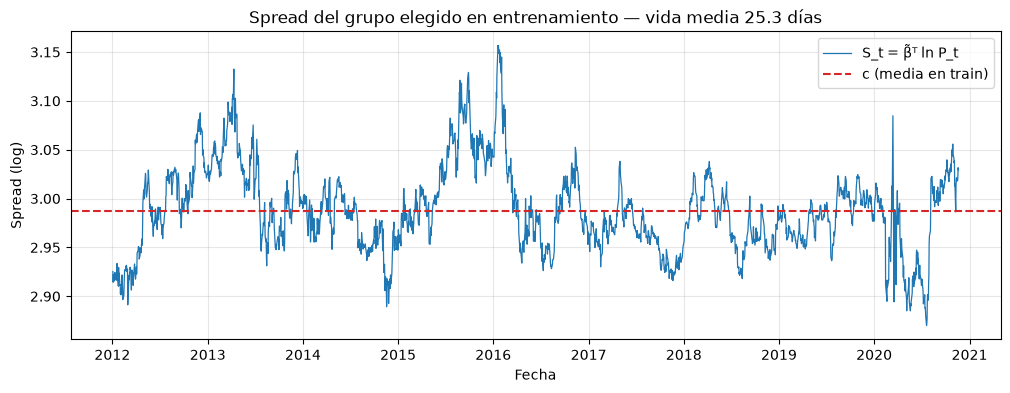

In [12]:
spread = build_spread(log_chosen, beta[chosen_tickers].to_numpy())
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spread.index, spread, linewidth=0.9, label="S_t = β̃ᵀ ln P_t")
ax.axhline(summary["intercept_c"], color="tab:red", linestyle="--", label="c (media en train)")
ax.set_title(f"Spread del grupo elegido en entrenamiento — vida media {summary['half_life_days']:.1f} días")
ax.set_xlabel("Fecha"); ax.set_ylabel("Spread (log)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Paso 7 — Estabilidad

Johansen móvil con ventana de 504 días y paso de 21, k fijo al de entrenamiento y la misma pata ancla. Cada ventana
usa solo datos pasados; se muestra toda la muestra como **diagnóstico** (la selección no usó prueba ni validación).

In [13]:
summarize_rolling(rolling, chosen_tickers)

,GLD_median,GDX_median,AEM_median,FNV_median,GLD_std,GDX_std,AEM_std,FNV_std,frac_windows_rank_ge_1,n_windows
split,,,,,,,,,,
train,1.0000,-0.6213,0.4588,-0.1475,0.0000,0.5519,0.3999,0.2514,0.3373,83
test,1.0000,-0.4947,0.5750,0.0079,0.0000,1.2142,1.0594,1.0494,0.4167,36
validation,1.0000,-0.1472,-0.3877,-0.0363,0.0000,6.3794,5.6373,1.3927,0.0000,35


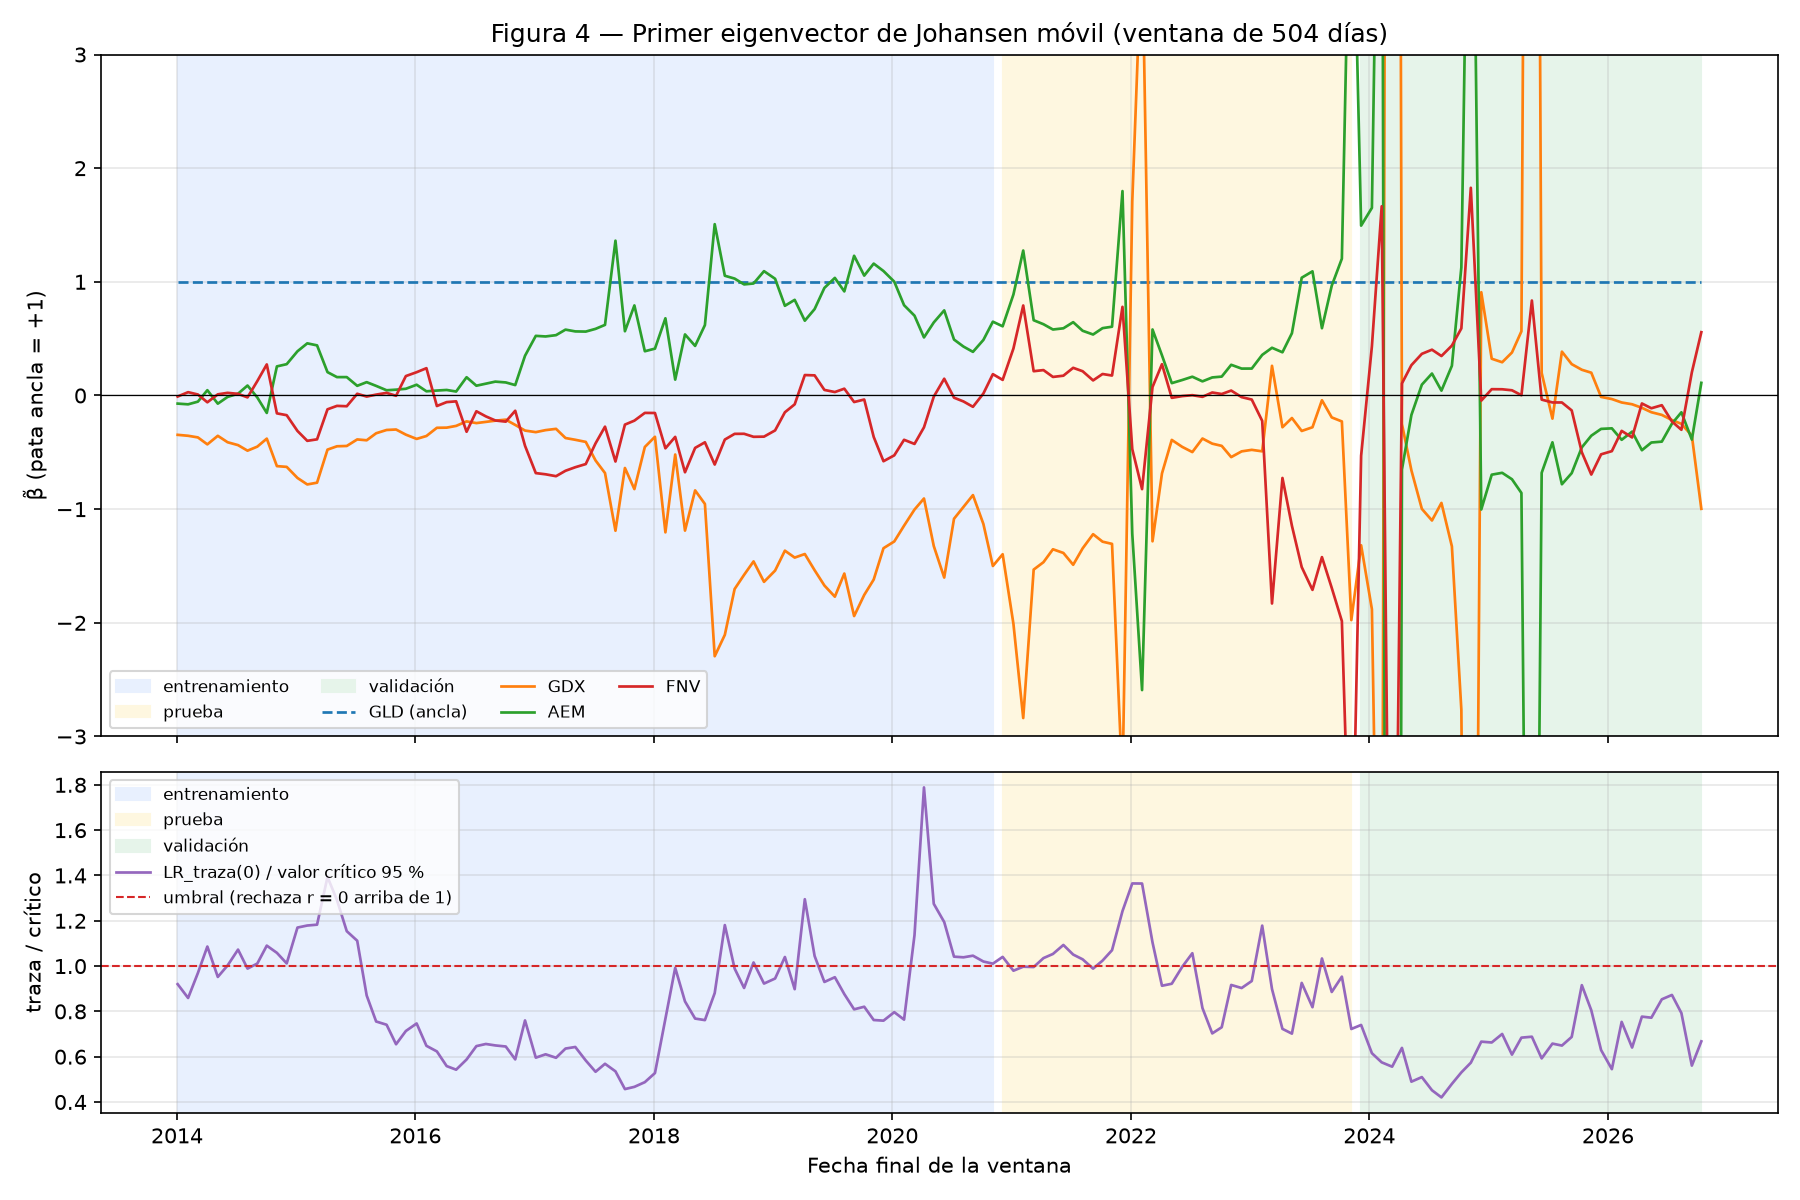

In [14]:
display(Image(filename=str(FIGURES / "fig04_eigenvector_movil.png")))

## Pruebas múltiples

In [15]:
pd.DataFrame(summary["multiple_testing"]).T

,groups_tested,johansen_reject_95,johansen_reject_99,expected_false_positives_95,pass_correlation,survive_all_stages,bonferroni_alpha
petroleras,126.0000,11.0000,2.0000,6.3000,4.0000,0.0000,0.0004
oro,70.0000,9.0000,2.0000,3.5000,66.0000,9.0000,0.0007
total,196.0000,20.0000,4.0000,9.8000,70.0000,9.0000,0.0003


## Discusión

- **Pruebas múltiples.** Se probaron 196 grupos. Al 95 %, Johansen rechaza r = 0 en 20 cuando el azar daría ≈ 9.8;
  en petroleras 11 contra 6.3 esperados (casi todo ruido), en oro 9 contra 3.5. Al 99 % solo quedan 4 grupos, y el
  elegido es uno de ellos (traza 61.3 > 54.7). Con Bonferroni (α / N ≈ 0.00026) las tablas de statsmodels no
  alcanzan para afirmarlo; la defensa es el racional económico del universo, haber fijado el criterio antes y la
  estabilidad.
- **Por qué es un grupo y no un par.** Ninguno de los 6 pares del grupo elegido es cointegrado por Engle–Granger,
  pero el grupo de 4 sí (EG del grupo p ≈ 0.006 con AEM como dependiente; Johansen r̂ = 1): es la idea (1) de la sesión 14, relaciones que necesitan tres o más patas.
- **Lectura económica de β̃.** Largo el spread = comprar oro (GLD) y Agnico Eagle, vender el ETF de mineras (GDX) y
  Franco-Nevada (regalías), en proporción a |β̃_i|. Es una relación entre el metal y dos formas distintas de
  exposición apalancada a él.
- **Estabilidad.** El grupo rechaza r = 0 en las dos mitades de entrenamiento (solo 4 de los 9 sobrevivientes lo
  hacen), pero el Johansen móvil muestra que con 2 años de datos la relación solo es significativa en una
  fracción de las ventanas y que los pesos se mueven (GDX pasa de ≈ −0.3 a ≈ −2 dentro de train). En validación
  (2023–2026, el gran rally del oro) ninguna ventana rechaza r = 0: la relación estática se debilita. Esto **no**
  cambia la selección (sería data snooping) y es justo la razón del filtro 1: pesos β_t que se adaptan.

## Para JME (parte 03, filtro 1)

- Inicialización: β_0 = β̃ de `johansen_summary.json` (`beta_normalized`), pata ancla **GLD** = +1, en **log-precios**.
- Estado del filtro 1 (notación de clase): z_t = (c_t, β_t^{GDX}, β_t^{AEM}, β_t^{FNV}), y_t = ln P_t^{GLD}.
  Ojo con el signo: con S_t = β̃ᵀ ln P_t, y_t = c_t − Σ β̃_i ln P_t^{(i)} + S_t.
- `artifacts/prices.parquet` ya lo escribe `main.py`: GLD, GDX, AEM, FNV con la columna `split`. Falta la figura 1.

## Resumen de resultados (parte 02)

**Pregunta:** ¿qué grupo de 4 activos comparte una tendencia estocástica común en entrenamiento (2012-01-03 →
2020-11-19), y con qué vector de pesos? Todo se calculó solo con entrenamiento y con un criterio fijado antes de correr.

**Embudo (196 grupos de 4: 126 de petroleras y 70 de oro)**

| Universo | Descartados por correlación | Descartados por Johansen | Sobreviven |
|---|---|---|---|
| Petroleras | 122 | 4 | 0 |
| Oro | 4 | 57 | 9 |

- Las petroleras casi no pasan el filtro de correlación (mediana por par 0.66) y los 4 grupos que pasan no son
  cointegrados. El oro sí se mueve en conjunto (mediana por par 0.73).
- Engle–Granger solo prioriza: todas las regresiones en niveles levantan la bandera de regresión espuria (R² > DW).

**Grupo elegido: GLD – GDX – AEM – FNV** (oro físico, ETF de mineras, Agnico Eagle, Franco-Nevada)

| Resultado | Valor |
|---|---|
| Johansen, traza r = 0 | 61.3 vs 47.9 (95 %) y 54.7 (99 %) → se rechaza |
| Johansen, máx. eigenvalor r = 0 | 37.4 vs 27.6 (95 %) → se rechaza |
| Rango r̂ | 1 por ambas pruebas (k_ar_diff = 1 por BIC, constante) |
| Vector normalizado β̃ (ancla GLD = +1) | GLD +1.000, GDX −0.569, AEM +0.400, FNV −0.371 |
| Constante c (media del spread en train) | 2.988 |
| ADF del spread | −4.68, p = 0.0001 → estacionario |
| Vida media | 25.3 días (rango operable 5–60) |
| Correlación media del grupo | 0.773 (supera 0.7 en 89 % de los días) |
| Los 4 activos son I(1) | sí (ADF en niveles no rechaza; en diferencias sí) |

- **Interpretación:** largo el spread = comprar GLD y AEM, vender GDX y FNV. Es la relación entre el metal y dos
  formas distintas de exposición apalancada a él.
- **Más de un par:** ninguno de los 6 pares es cointegrado por Engle–Granger, pero el grupo sí. Es una relación que
  necesita más de dos patas.
- **Los otros 3 vectores** tienen vidas medias de 72 a 452 días y no son operables.

**Pruebas múltiples:** Johansen rechaza r = 0 en 20 de 196 grupos cuando el azar daría ≈ 9.8 al 5 %; al 99 % quedan 4
y el elegido es uno de ellos. Defensas: universos con justificación económica, criterio fijado antes de correr,
número total de grupos reportado y estabilidad.

**Estabilidad:** el grupo es cointegrado en ambas mitades de entrenamiento (solo 4 de los 9 sobrevivientes lo son).
El Johansen móvil de 2 años rechaza r = 0 en 34 % de las ventanas de train, 42 % en prueba y 0 % en validación, y los
pesos se mueven en el tiempo (figura 4). La relación estática se debilita en 2023–2026: eso motiva el filtro de
Kalman 1 con pesos dinámicos y es una limitación a discutir. No se cambió la selección por esto (sería data snooping).

**Siguiente paso:** el filtro 1 (parte 03) arranca con β̃ como inicialización sobre `artifacts/prices.parquet`.